# Human Activity Recognition with a Hidden Markov Model (from scratch, NumPy)
Hidden states = activities (standing, walking, jumping, still). Observations = feature vectors computed from accelerometer + gyroscope windows.

**Data:** recorded by me with Sensor Logger on an iPhone XR (accelerometer + gyroscope, x/y/z, ~100 Hz). One labelled CSV per recording is in `data/` (created by `prepare_data.py`).

In [1]:
import glob, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from hmm import GaussianHMM          # my numpy implementation (hmm.py)

STATES = ["standing", "walking", "jumping", "still"]
WIN, STEP, TRIM = 200, 50, 1.0       # 2 s windows, 75 % overlap, trim 1 s at both ends of each recording
SEED = 42
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

# ---- Unseen (test) recordings: never used for training or for standardisation ----
TEST = ["jumping_09","jumping_10","standing_09","standing_10","walking_09","walking_10",
        "still_05","still_09","still_10"]   # still_05 / still_10 deliberately contain movement (kept as unseen to expose errors)
# Recordings where I changed the phone position (fill in the file names; shown in the per-recording table)
POSITION_CHANGED = []

## 1. Data loading and sampling rate

In [2]:
raw, rows = {}, []
for f in sorted(glob.glob("data/*.csv")):
    name = os.path.basename(f)[:-4]
    d = pd.read_csv(f); t = d["seconds_elapsed"]
    fs = (len(d)-1)/(t.iloc[-1]-t.iloc[0])
    raw[name] = d[(t > TRIM) & (t < t.iloc[-1]-TRIM)].reset_index(drop=True)
    rows.append(dict(recording=name, activity=name.split("_")[0], samples=len(d), seconds=round(t.iloc[-1]-t.iloc[0],1),
                     rate_hz=round(fs,1), split="test" if name in TEST else "train"))
meta = pd.DataFrame(rows)
FS = meta.rate_hz.mean()
print(f"Sampling rate: {FS:.1f} Hz (iPhone XR)   |   recordings: {len(meta)}")
meta.groupby(["activity","split"]).size().unstack(fill_value=0)

Sampling rate: 99.4 Hz (iPhone XR)   |   recordings: 39


split,test,train
activity,,
jumping,2,7
standing,2,8
still,3,7
walking,2,8


## 2. Raw signals (one example per activity)

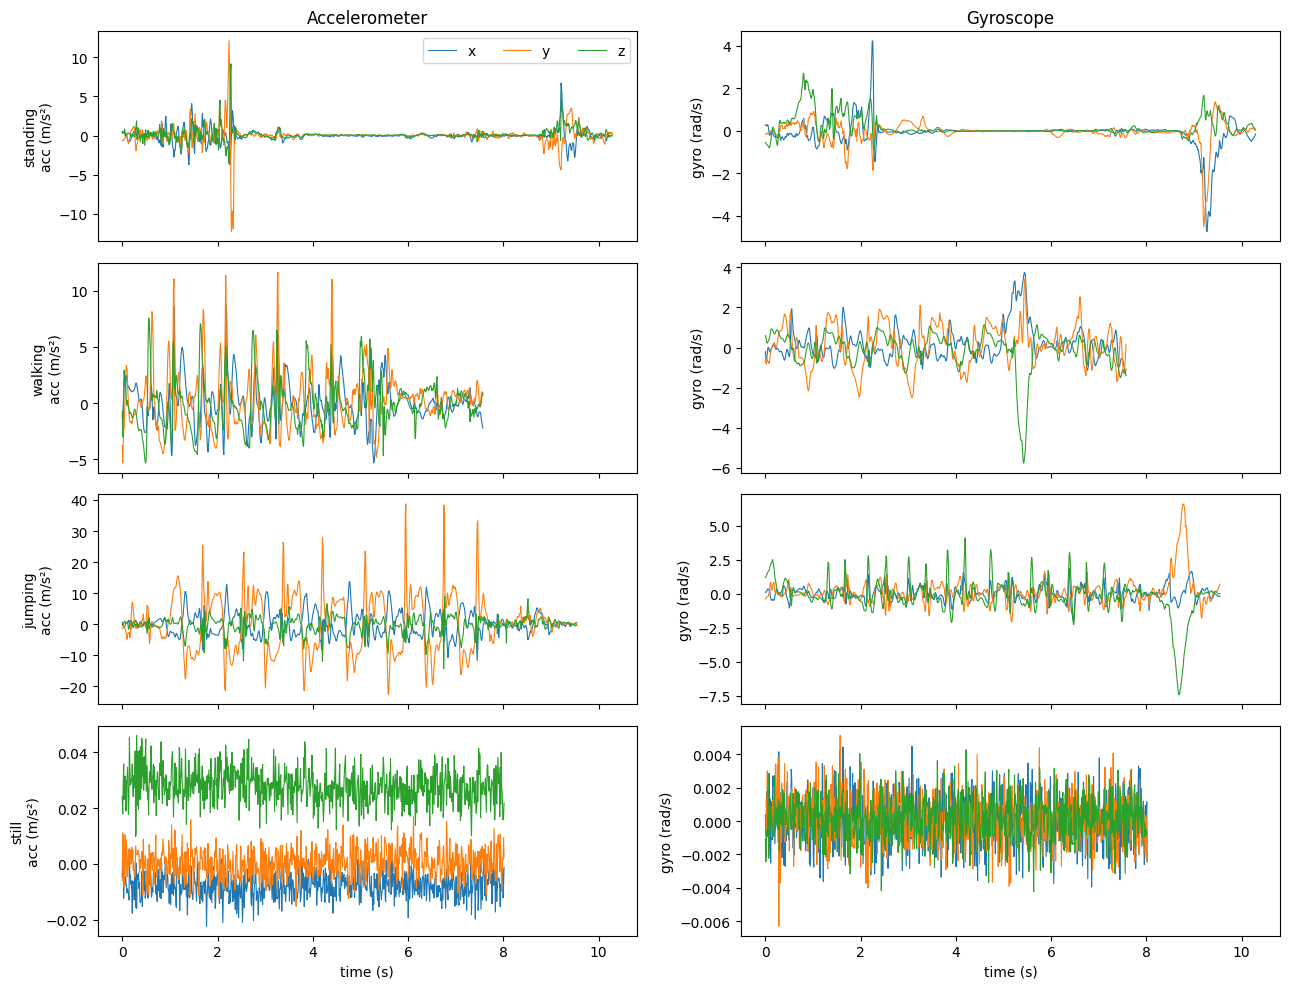

In [3]:
ex = {"standing":"standing_01","walking":"walking_01","jumping":"jumping_01","still":"still_01"}
fig, ax = plt.subplots(4, 2, figsize=(13, 10), sharex=True)
for i, (act, n) in enumerate(ex.items()):
    d = raw[n]; t = d.seconds_elapsed - d.seconds_elapsed.iloc[0]
    for c in "xyz":
        ax[i,0].plot(t, d[f"acc_{c}"], lw=.8, label=c); ax[i,1].plot(t, d[f"gyr_{c}"], lw=.8, label=c)
    ax[i,0].set_ylabel(f"{act}\nacc (m/s²)"); ax[i,1].set_ylabel("gyro (rad/s)")
ax[0,0].set_title("Accelerometer"); ax[0,1].set_title("Gyroscope"); ax[0,0].legend(ncol=3)
ax[3,0].set_xlabel("time (s)"); ax[3,1].set_xlabel("time (s)")
plt.tight_layout(); plt.savefig("figures/raw_signals.png", dpi=200); plt.show()

## 3. Feature extraction (per 2 s window)
Most features use the **magnitude** of the 3-axis signal, so they do not depend on how the phone is oriented (useful because I changed the phone position in some recordings).

| Domain | Features |
|---|---|
| Time | mean of acc magnitude, std, signal magnitude area (SMA), mean absolute correlation between acc axes; gyro std and SMA |
| Frequency | dominant frequency, spectral energy (FFT), share of energy in 0.3-3 Hz and 3-20 Hz bands (acc); dominant frequency and spectral energy (gyro) |

Std, SMA and energy are log-transformed because they span several orders of magnitude (still ≈ 0.01, jumping ≈ 7).

In [4]:
def spectrum(x):
    x = x - x.mean(); P = np.abs(np.fft.rfft(x*np.hanning(len(x))))**2/len(x); f = np.fft.rfftfreq(len(x), 1/FS)
    band = (f >= 0.3) & (f <= 20); tot = P[band].sum() + 1e-12
    return f[band][np.argmax(P[band])], tot, P[(f>=0.3)&(f<3)].sum()/tot, P[(f>=3)&(f<=20)].sum()/tot

def window_features(A, G):
    a, g = np.linalg.norm(A, axis=1), np.linalg.norm(G, axis=1)
    ad, ae, alo, ahi = spectrum(a); gd, ge, _, _ = spectrum(g)
    c = np.nan_to_num(np.corrcoef(A.T)); corr = np.mean(np.abs([c[0,1], c[0,2], c[1,2]]))
    L = lambda v: np.log10(v + 1e-4)
    return [a.mean(), L(a.std()), L(np.abs(A).sum(1).mean()), corr, ad, L(ae), alo, ahi,
            L(g.std()), L(np.abs(G).sum(1).mean()), gd, L(ge)]

FEATS = ["acc_mean","acc_std(log)","acc_SMA(log)","acc_axis_corr","acc_dom_freq","acc_spec_energy(log)",
         "acc_low_band_ratio","acc_high_band_ratio","gyr_std(log)","gyr_SMA(log)","gyr_dom_freq","gyr_spec_energy(log)"]

def windows(d):
    A, G = d[["acc_x","acc_y","acc_z"]].values, d[["gyr_x","gyr_y","gyr_z"]].values
    return np.array([window_features(A[i:i+WIN], G[i:i+WIN]) for i in range(0, len(d)-WIN+1, STEP)])

F = {n: windows(d) for n, d in raw.items()}
label = lambda n: STATES.index(n.split("_")[0])
rec_df = pd.concat([pd.DataFrame(F[n], columns=FEATS).assign(activity=n.split("_")[0], recording=n, split="test" if n in TEST else "train") for n in F])
print(len(rec_df), "windows")
rec_df.groupby(["activity","split"]).size().unstack(fill_value=0)

516 windows


split,test,train
activity,,
jumping,26,89
standing,31,134
still,23,78
walking,27,108


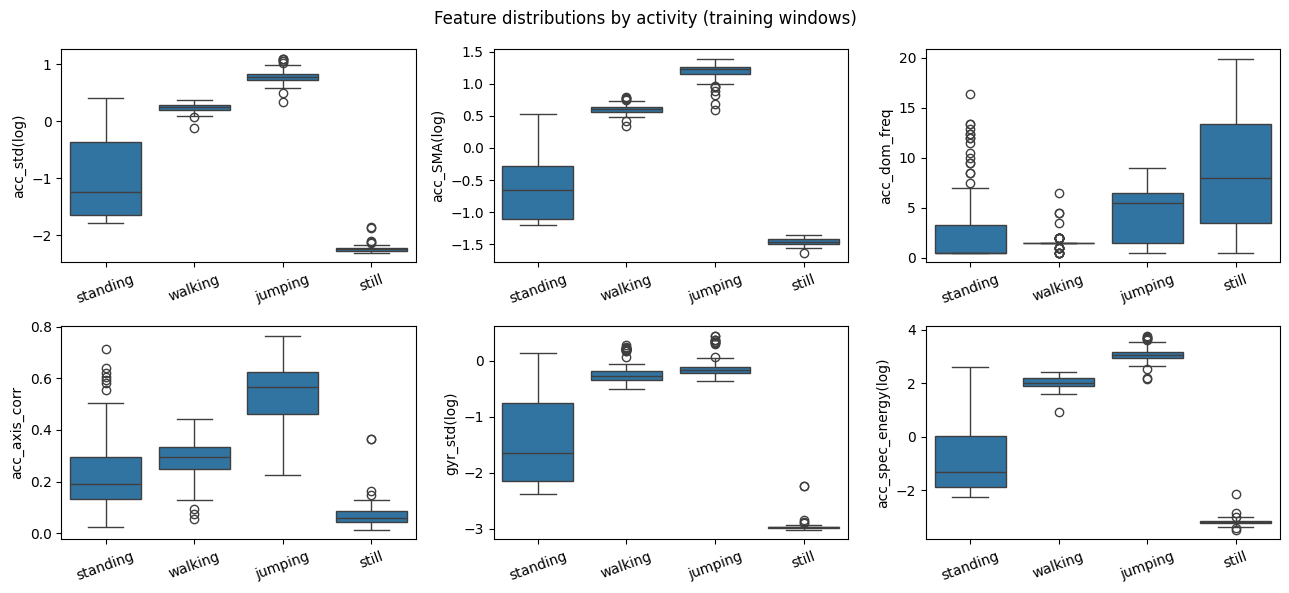

In [5]:
show = ["acc_std(log)","acc_SMA(log)","acc_dom_freq","acc_axis_corr","gyr_std(log)","acc_spec_energy(log)"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, f in zip(ax.ravel(), show):
    sns.boxplot(data=rec_df[rec_df.split=="train"], x="activity", y=f, order=STATES, ax=a); a.set_xlabel(""); a.tick_params(axis="x", rotation=20)
plt.suptitle("Feature distributions by activity (training windows)"); plt.tight_layout()
plt.savefig("figures/feature_boxplots.png", dpi=200); plt.show()

## 4. HMM definition
* **Hidden states Z:** standing, walking, jumping, still
* **Observations X:** standardised 12-dim feature vector per window
* **Emissions B:** diagonal Gaussian per state (mean and variance estimated from the labelled training windows)
* **Transitions A, initial π:** estimated by counting (with +1 smoothing) from state sequences
* **Decoding:** Viterbi (log-space)

**Important about the transitions.** All my recordings contain a single activity, so real transitions between activities were not recorded. I therefore *stitch* sequences: each training sequence is the four activities in a random order, each segment a randomly chosen real training recording (windows are computed per recording first, so no window straddles two activities). The transition matrix therefore reflects this stitching procedure, not natural behaviour.

In [6]:
train_names = [n for n in F if n not in TEST]
Xtr = np.vstack([F[n] for n in train_names]); ztr = np.concatenate([[label(n)]*len(F[n]) for n in train_names])
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9            # standardisation uses training data only
S = lambda X: (X - mu)/sd

rng = np.random.default_rng(SEED)
by_act = {k: [n for n in train_names if label(n) == k] for k in range(4)}
train_seqs = []
for _ in range(50):
    z = []
    for k in rng.permutation(4):
        z += [k]*len(F[rng.choice(by_act[k])])
    train_seqs.append(np.array(z))

hmm = GaussianHMM(4).fit_emissions(S(Xtr), ztr).fit_transitions(train_seqs)
print("Initial probabilities pi:", dict(zip(STATES, hmm.pi.round(3))))
A_df = pd.DataFrame(hmm.A, index=STATES, columns=STATES).round(3); A_df

Initial probabilities pi: {'standing': np.float64(0.241), 'walking': np.float64(0.296), 'jumping': np.float64(0.185), 'still': np.float64(0.278)}


,standing,walking,jumping,still
standing,0.950,0.014,0.018,0.018
walking,0.026,0.938,0.020,0.017
jumping,0.025,0.020,0.933,0.022
still,0.014,0.025,0.031,0.930


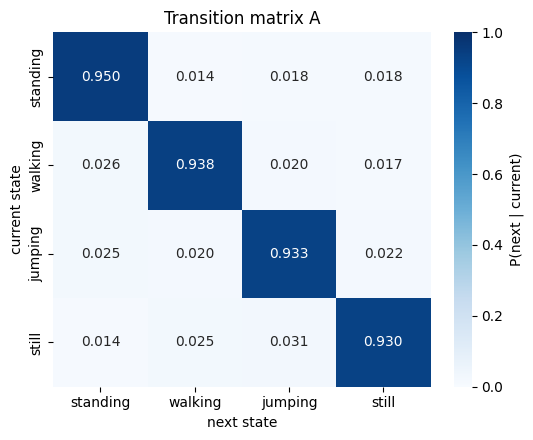

In [7]:
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(A_df, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "P(next | current)"})
plt.xlabel("next state"); plt.ylabel("current state"); plt.title("Transition matrix A")
plt.tight_layout(); plt.savefig("figures/transition_heatmap.png", dpi=200); plt.show()

## 5. Evaluation on unseen recordings

In [8]:
rng_t = np.random.default_rng(SEED+1)
pool = {k: [n for n in TEST if label(n) == k] for k in range(4)}
test_seqs = []                                       # each unseen recording is used exactly once
for i in range(max(len(v) for v in pool.values())):
    names = [pool[k][i] for k in rng_t.permutation(4) if i < len(pool[k])]
    test_seqs.append(names)

y_true, y_hmm, y_ind, rec = [], [], [], []
decoded = []
for names in test_seqs:
    X = np.vstack([S(F[n]) for n in names]); z = np.concatenate([[label(n)]*len(F[n]) for n in names])
    p, _ = hmm.viterbi(X); q = hmm.predict_independent(X)
    y_true += list(z); y_hmm += list(p); y_ind += list(q); rec += sum([[n]*len(F[n]) for n in names], [])
    decoded.append((names, z, p))
y_true, y_hmm, y_ind, rec = map(np.array, (y_true, y_hmm, y_ind, rec))

def confusion(t, p):
    cm = np.zeros((4,4), int)
    for a, b in zip(t, p): cm[a, b] += 1
    return cm

def metrics_table(cm):
    N = cm.sum(); out = []
    for k, s in enumerate(STATES):
        TP = cm[k,k]; FN = cm[k].sum()-TP; FP = cm[:,k].sum()-TP; TN = N-TP-FN-FP
        out.append(dict(Activity=s, Samples=int(cm[k].sum()), Sensitivity=TP/(TP+FN), Specificity=TN/(TN+FP), Accuracy=(TP+TN)/N))
    t = pd.DataFrame(out); t["Overall accuracy"] = np.trace(cm)/N; return t.round(3)

cm_hmm = confusion(y_true, y_hmm); table = metrics_table(cm_hmm)
table.to_csv("results/evaluation_table.csv", index=False)
print("HMM (Viterbi) overall accuracy:", round(np.trace(cm_hmm)/cm_hmm.sum(), 3), "| test windows:", len(y_true))
table

HMM (Viterbi) overall accuracy: 0.916 | test windows: 107


,Activity,Samples,Sensitivity,Specificity,Accuracy,Overall accuracy
0,standing,31,0.968,0.895,0.916,0.916
1,walking,27,1.000,0.988,0.991,0.916
2,jumping,26,1.000,1.000,1.000,0.916
3,still,23,0.652,1.000,0.925,0.916


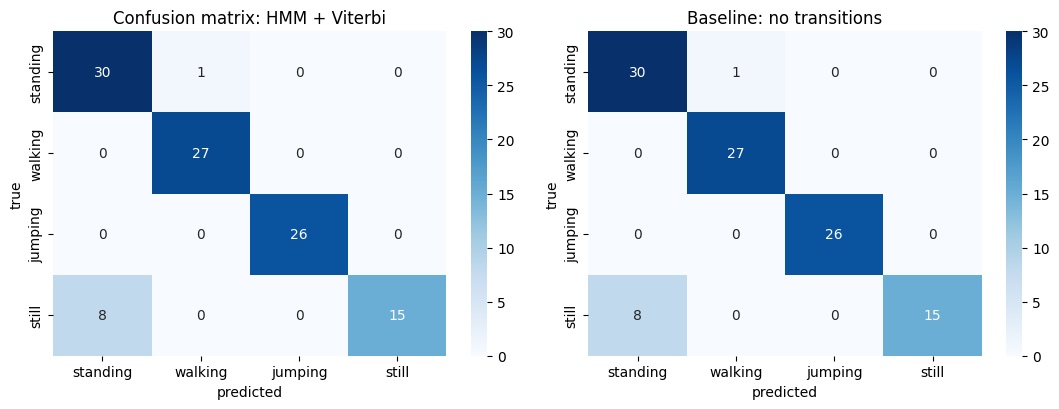

Baseline (emissions only) accuracy: 0.916


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(pd.DataFrame(cm_hmm, index=STATES, columns=STATES), annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set_title("Confusion matrix: HMM + Viterbi"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
cm_ind = confusion(y_true, y_ind)
sns.heatmap(pd.DataFrame(cm_ind, index=STATES, columns=STATES), annot=True, fmt="d", cmap="Blues", ax=ax[1]); ax[1].set_title("Baseline: no transitions"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", dpi=200); plt.show()
print("Baseline (emissions only) accuracy:", round(np.trace(cm_ind)/cm_ind.sum(), 3))

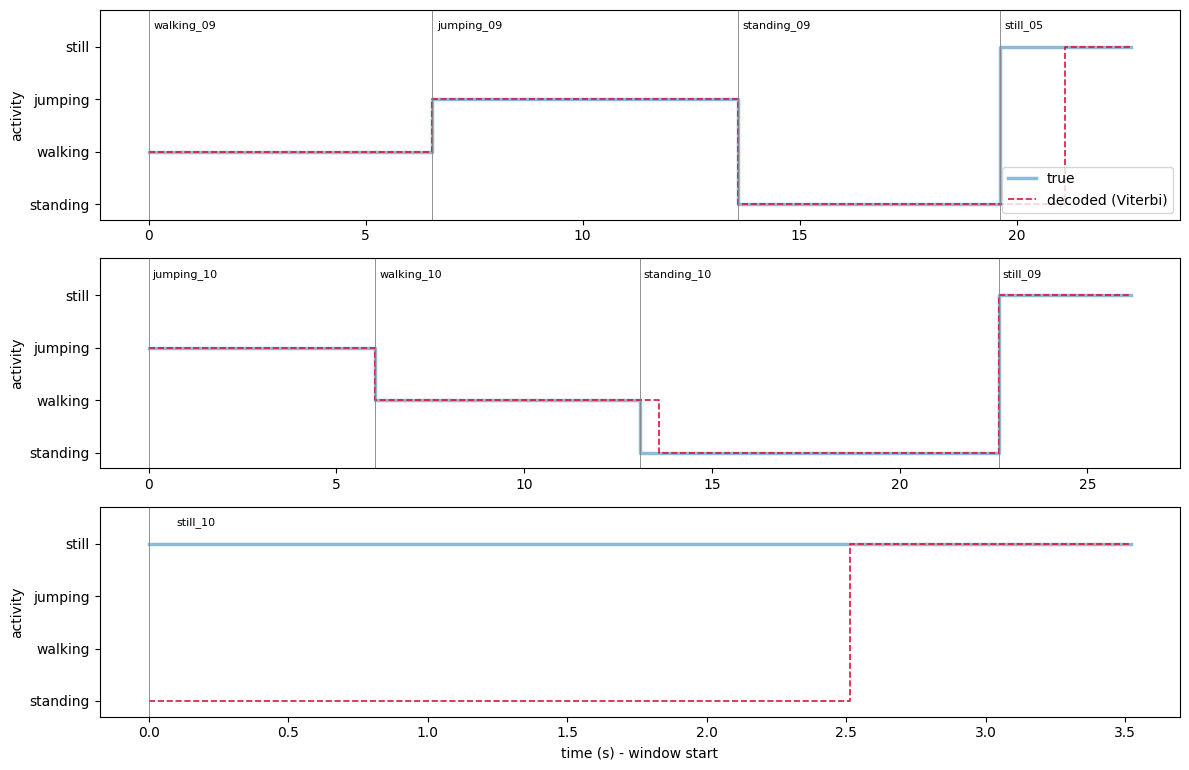

In [10]:
fig, ax = plt.subplots(len(decoded), 1, figsize=(12, 2.6*len(decoded)))
ax = np.atleast_1d(ax)
for a, (names, z, p) in zip(ax, decoded):
    x = np.arange(len(z)) * STEP/FS
    a.step(x, z, where="post", lw=2.5, alpha=.5, label="true"); a.step(x, p, where="post", lw=1.2, color="crimson", ls="--", label="decoded (Viterbi)")
    a.set_yticks(range(4)); a.set_yticklabels(STATES); a.set_ylabel("activity")
    b = 0
    for n in names:
        a.axvline(b*STEP/FS, color="gray", lw=.6); a.text(b*STEP/FS+.1, 3.35, n, fontsize=8); b += len(F[n])
    a.set_ylim(-.3, 3.7)
ax[0].legend(loc="lower right"); ax[-1].set_xlabel("time (s) - window start")
plt.tight_layout(); plt.savefig("figures/decoded_sequences.png", dpi=200); plt.show()

In [11]:
per = pd.DataFrame({"recording": rec, "ok": y_hmm == y_true}).groupby("recording").ok.agg(["size","mean"]).rename(columns={"size":"windows","mean":"accuracy"}).round(2)
per["phone position changed"] = ["yes" if n in POSITION_CHANGED else "" for n in per.index]
per

,windows,accuracy,phone position changed
recording,,,
jumping_09,14,1.00,
jumping_10,12,1.00,
standing_09,12,1.00,
standing_10,19,0.95,
still_05,7,0.57,
still_09,8,1.00,
still_10,8,0.38,
walking_09,13,1.00,
walking_10,14,1.00,


### Why were `still_05` and `still_10` misclassified?

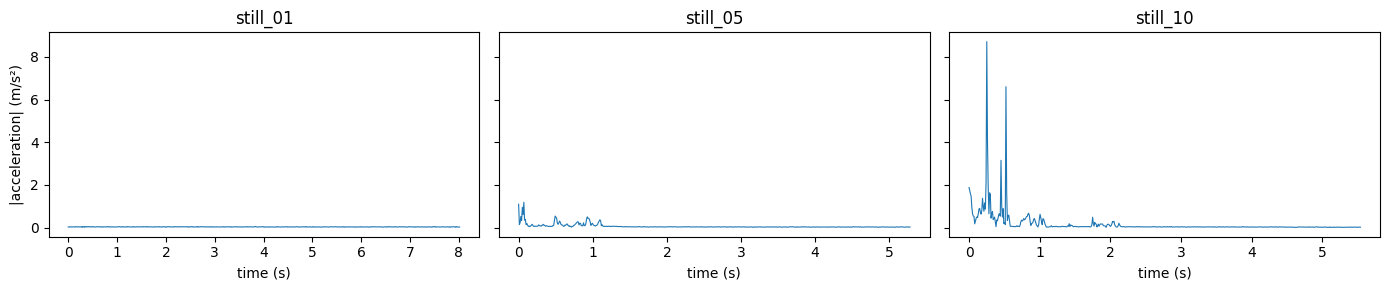

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for a, n in zip(ax, ["still_01", "still_05", "still_10"]):
    d = raw[n]; a.plot(d.seconds_elapsed - d.seconds_elapsed.iloc[0], np.linalg.norm(d[["acc_x","acc_y","acc_z"]].values, axis=1), lw=.8)
    a.set_title(n); a.set_xlabel("time (s)")
ax[0].set_ylabel("|acceleration| (m/s²)"); plt.tight_layout(); plt.savefig("figures/still_outliers.png", dpi=200); plt.show()

## 6. Algorithm choice (brief)
* **Supervised parameter estimation (counting + Gaussian fit)**: my recordings are labelled, so the maximum-likelihood parameters can be computed directly. This gives stable emissions per activity and better sensitivity/specificity than an unsupervised fit, whose states may not line up with the labels.
* **Baum-Welch (EM)** is only needed if labels are unavailable; it can converge to a local optimum and its states would need to be mapped to activities afterwards.
* **Viterbi** returns the single most likely state sequence, so it is the decoder to use for per-window predictions (sensitivity, specificity, accuracy). The forward algorithm only gives sequence likelihoods or filtered probabilities.
* Comparing Viterbi to the no-transition baseline shows how much the temporal model adds.